In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.impute import SimpleImputer
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import accuracy_score, r2_score, root_mean_squared_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import plot_tree
from sklearn.model_selection import GridSearchCV

In [2]:
df = pd.read_csv(r"/Users/kashvivirmani/Desktop/Delhi_UHI_Project/Data/Processed/cleaned_dataset.csv")

df.head()

,Latitude,Longitude,AirTemp,DistanceToWater,Elevation,Humidity,LST,LULC,MNDWI,NDBI,NDVI,Population,Slope,WindSpeed,LULC_Name
0,28.632720,77.204349,32.490555,1065.082156,223,28.763419,41.820506,6,-0.103358,-0.061668,0.161954,190.287857,3.489779,1.422401,Built Area
1,28.614477,77.114090,32.618237,4417.420062,219,28.276358,46.014417,6,-0.089072,-0.004090,0.071271,318.664734,1.854334,1.422094,Built Area
2,28.783908,77.106962,32.277801,56.568542,211,29.923939,44.336169,0,-0.086957,-0.014011,0.089721,0.000000,1.406886,1.355455,Water
3,28.660692,77.147372,32.479869,1059.056184,216,29.162266,45.623053,6,-0.079266,-0.051205,0.125391,268.919067,2.307262,1.391453,Built Area
4,28.814437,76.991782,32.366906,1223.764683,226,29.204621,50.153639,7,-0.151679,0.025338,0.100419,0.000000,4.263645,1.359317,Bare Ground


In [3]:
df = df.drop(columns=["LULC"])

In [4]:
# One hot encoding
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
encoded = ohe.fit_transform(df[["LULC_Name"]])

In [5]:
encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(["LULC_Name"]),
    index = df.index
)

In [6]:
df = pd.concat([df.drop(columns=["LULC_Name"]),encoded_df], axis=1)

In [7]:
df.columns

Index(['Latitude', 'Longitude', 'AirTemp', 'DistanceToWater', 'Elevation',
       'Humidity', 'LST', 'MNDWI', 'NDBI', 'NDVI', 'Population', 'Slope',
       'WindSpeed', 'LULC_Name_Built Area', 'LULC_Name_Crops',
       'LULC_Name_Flooded Vegetation', 'LULC_Name_Grass', 'LULC_Name_Shrub',
       'LULC_Name_Trees', 'LULC_Name_Water'],
      dtype='str')

In [8]:
X = df.drop(columns=["LST"])
y = df["LST"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=43
)

In [10]:
model = DecisionTreeRegressor()
model.fit(X_train, y_train)

,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_node

In [11]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

In [12]:
print(f"MSE of training data = {mean_squared_error(y_train, y_pred_train)}")
print(f"MSE of testing data = {mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

MSE of training data = 0.0
MSE of testing data = 3.7523506419868613
r2_score of training data = 1.0
r2_score of testing data = 0.6668109889906986


## The above model is highly overfit

In [13]:
full_tree = DecisionTreeRegressor(random_state=42, max_depth=15, min_samples_split=10)
full_tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes m

In [14]:
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alpha = path.ccp_alphas
# ccp_alpha = ccp_alpha[::10]
ccp_alpha.shape

(986,)

In [15]:
param_grid = {"ccp_alpha" : ccp_alpha}
classifier = full_tree
grid_search = GridSearchCV(
    classifier,
    param_grid,
    scoring = "r2",
    cv = 5
)
grid_search.fit(X_train, y_train)
best_r2_score = grid_search.best_score_
best_alpha = grid_search.best_params_['ccp_alpha']

In [16]:
print(best_r2_score)
print(best_alpha)

0.7652816293120536
0.005190585471482025


In [17]:
best_model = DecisionTreeRegressor(random_state=42, max_depth=15, min_samples_split=10, ccp_alpha=best_alpha)
best_model.fit(X_train, y_train)

y_pred_train = best_model.predict(X_train)
y_pred_test = best_model.predict(X_test)

print(f"MSE of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"MSE of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

MSE of training data = 1.43853601188824
MSE of testing data = 1.620036452634667
r2_score of training data = 0.8211875525603047
r2_score of testing data = 0.7669565890375969


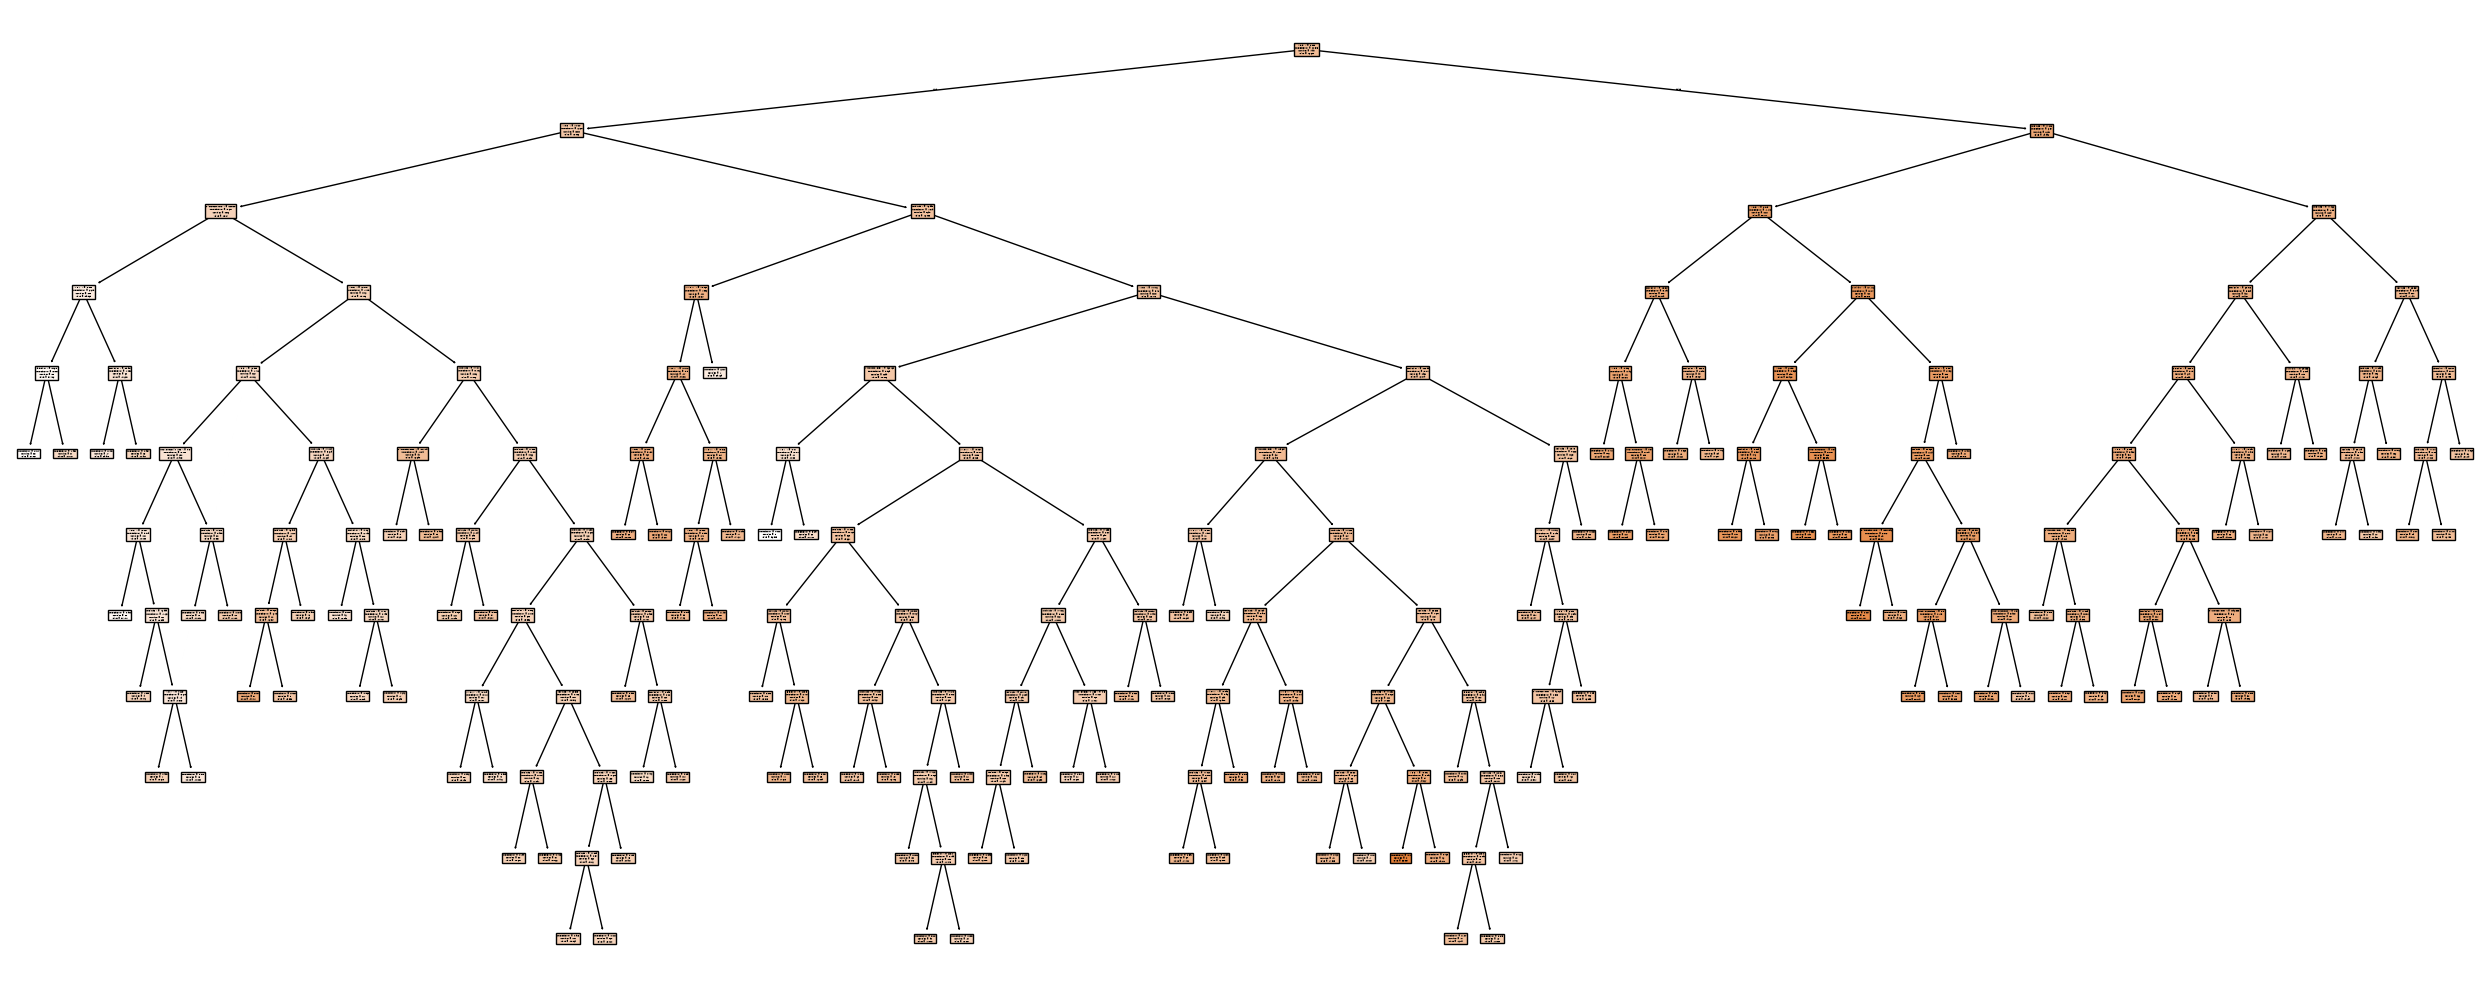

In [18]:
plt.figure(figsize=(25,10))
plot_tree(
    best_model,
    feature_names=X.columns,
    filled=True
)
plt.tight_layout()
plt.show()